In [1]:
import os

In [2]:
import meshio
import numpy as np
import deepxde as dde
import matplotlib.pyplot as plt

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [3]:
mesh = meshio.read("pipe_bend2.msh")

all_points = mesh.points[:, 0:2]

print("----Dignostics----")
print("Available keys in cell_sets_dict:", list(mesh.cell_sets_dict.keys()))
print("Available keys in field_data:", list(mesh.field_data.keys()))


----Dignostics----
Available keys in cell_sets_dict: []
Available keys in field_data: ['inlet', 'outlet', 'walls', 'fluid']


In [4]:
mesh = meshio.read("pipe_bend2.msh")

all_coords = mesh.points

inlet_nodes = set()
outlet_nodes = set()
walls_nodes = set()
fluid_nodes = set()

# 2. Mapping physical IDs from your new $PhysicalNames block (15, 16, 17, 19)
group_mapping = {15: inlet_nodes, 16: outlet_nodes, 17: walls_nodes, 19: fluid_nodes}

for block_idx, cell_block in enumerate(mesh.cells):
    if "gmsh:physical" in mesh.cell_data:
        tags = mesh.cell_data["gmsh:physical"][block_idx]
        elements_node_indices = cell_block.data
        
        for i, tag in enumerate(tags):
            if tag in group_mapping:
                group_mapping[tag].update(elements_node_indices[i])

# 4. Extract complete 3D coordinates (using all 3 columns [:, 0:3])
X_inlet  = all_coords[list(inlet_nodes)][:, 0:3]
X_outlet = all_coords[list(outlet_nodes)][:, 0:3]
X_walls  = all_coords[list(walls_nodes)][:, 0:3]
X_domain = all_coords[list(fluid_nodes)][:, 0:3]

print("--- Extracted 3D Spatial Coordinate Shapes ---")
print(f"X_inlet 3D Shape:  {X_inlet.shape}")
print(f"X_outlet 3D Shape: {X_outlet.shape}")
print(f"X_walls 3D Shape:  {X_walls.shape}")
print(f"X_domain 3D Shape: {X_domain.shape} <-- Fluid domain successfully populated!")

# 5. Stack everything together to initialize the DeepXDE PointCloud geometry
# DeepXDE evaluates the PDE residuals across all points passed into this array
X_all_training = np.vstack((X_domain, X_inlet, X_outlet, X_walls))
print(f"Total Unified 3D Training Points: {X_all_training.shape}")

# Initialize the DeepXDE point cloud geometry configuration
geom = dde.geometry.PointCloud(X_all_training)



--- Extracted 3D Spatial Coordinate Shapes ---
X_inlet 3D Shape:  (179, 3)
X_outlet 3D Shape: (181, 3)
X_walls 3D Shape:  (5591, 3)
X_domain 3D Shape: (13792, 3) <-- Fluid domain successfully populated!
Total Unified 3D Training Points: (19743, 3)


This code scales the values which are big like 150 mm for length and nothing else. This step is used to chances of coming [nan, nan] in training process

In [20]:
# 

# 1. Compute global normalization bounds from raw mesh points
raw_coords = mesh.points
X_min_vals = np.min(raw_coords, axis=0)
spatial_span = np.max(raw_coords) - np.min(raw_coords)

# 2. Rescale to safely sit between 0.0 and 1.0 (Fixes the exp overflow!)
all_coords = (raw_coords - X_min_vals) / spatial_span

inlet_nodes = set()
outlet_nodes = set()
walls_nodes = set()
fluid_nodes = set()

# 3. Precise dictionary mapping (15=Inlet, 16=Outlet, 17=Walls, 19=Fluid)
group_mapping = {15: inlet_nodes, 16: outlet_nodes, 17: walls_nodes, 19: fluid_nodes}

for block_idx, cell_block in enumerate(mesh.cells):
    if "gmsh:physical" in mesh.cell_data:
        tags = mesh.cell_data["gmsh:physical"][block_idx]
        elements_node_indices = cell_block.data
        
        for i, tag in enumerate(tags):
            if tag in group_mapping:
                group_mapping[tag].update(elements_node_indices[i])

# 4. Extract unique scaled sub-arrays (Double check indices!)
X_inlet  = all_coords[list(inlet_nodes)][:, 0:3]
X_outlet = all_coords[list(outlet_nodes)][:, 0:3]  # <-- Fixed to use outlet_nodes
X_walls  = all_coords[list(walls_nodes)][:, 0:3]
X_domain = all_coords[list(fluid_nodes)][:, 0:3]

print("--- Point Count Verification ---")
print(f"Fluid Domain Nodes: {X_domain.shape[0]}")
print(f"Inlet Border Nodes: {X_inlet.shape[0]}")
print(f"Outlet Border Nodes:{X_outlet.shape[0]}")
print(f"Wall Border Nodes:  {X_walls.shape[0]}")

""" This code is to create dense boundary
# Quick trick to double your boundary resolution by inserting midpoints
midpoints = (X_walls[:-1] + X_walls[1:]) / 2.0
X_walls_dense = np.vstack((X_walls, midpoints))

# Re-combine into your training coordinates
X_all_training = np.vstack((X_domain, X_inlet, X_outlet, X_walls_dense))
geom = dde.geometry.PointCloud(X_all_training)
# 5. Build Unified Training Set"""
X_all_training = np.vstack((X_domain, X_inlet, X_outlet, X_walls))
print(f"Total Combined Training Nodes: {X_all_training.shape[0]} <-- This should match your original count!")

geom = dde.geometry.PointCloud(X_all_training)


--- Point Count Verification ---
Fluid Domain Nodes: 13792
Inlet Border Nodes: 179
Outlet Border Nodes:181
Wall Border Nodes:  5591
Total Combined Training Nodes: 19743 <-- This should match your original count!


/tmp/ipykernel_12473/3828630995.py:18: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


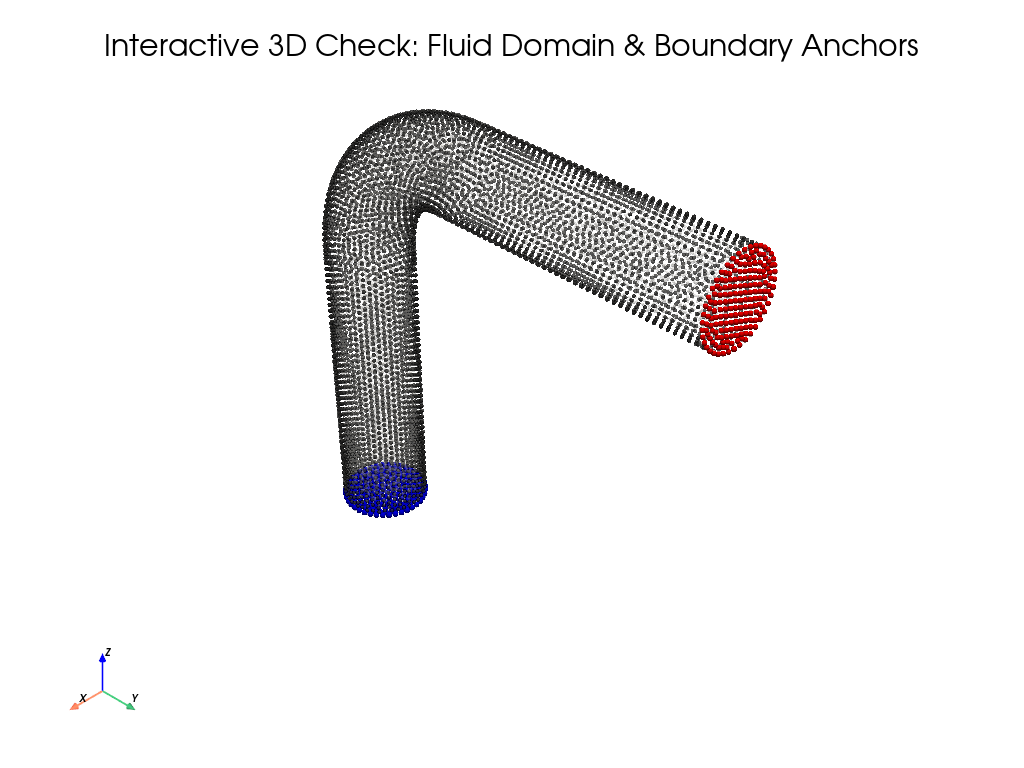

In [21]:
import pyvista as pv
import numpy as np

# 1. Initialize a PyVista plotting window
plotter = pv.Plotter()

# 2. Add each extracted 3D point group as a colored point cloud mesh
plotter.add_points(np.array(X_domain), color="lightgray", point_size=3.0, opacity=0.3, render_points_as_spheres=True, name="Fluid")
plotter.add_points(np.array(X_inlet),  color="blue",      point_size=6.0, render_points_as_spheres=True, name="Inlet")
plotter.add_points(np.array(X_outlet), color="red",       point_size=6.0, render_points_as_spheres=True, name="Outlet")
plotter.add_points(np.array(X_walls),  color="black",     point_size=4.0, opacity=0.7, render_points_as_spheres=True, name="Walls")

# 3. Add axes descriptors and title orientation
plotter.add_axes()
plotter.add_title("Interactive 3D Check: Fluid Domain & Boundary Anchors", font_size=12)

# 4. Open the interactive window
plotter.show()


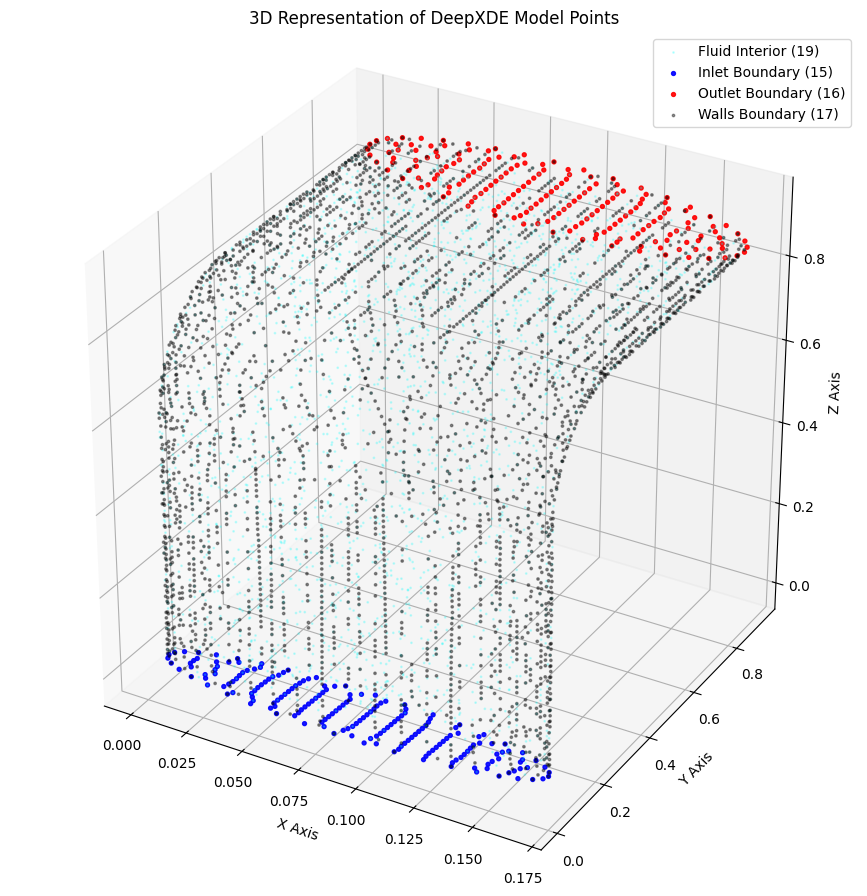

In [22]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 1. Plot a fraction of the interior fluid volume points so the chart renders smoothly
# [::5] skips every 5th point to keep your screen responsive
ax.scatter(X_domain[::5, 0], X_domain[::5, 1], X_domain[::5, 2], s=1, c='cyan', alpha=0.2, label='Fluid Interior (19)')

# 2. Scatter your explicit boundary anchors
ax.scatter(X_inlet[:, 0],  X_inlet[:, 1],  X_inlet[:, 2],  s=8, c='blue',  alpha=0.9, label='Inlet Boundary (15)')
ax.scatter(X_outlet[:, 0], X_outlet[:, 1], X_outlet[:, 2], s=8, c='red',   alpha=0.9, label='Outlet Boundary (16)')
ax.scatter(X_walls[::2, 0], X_walls[::2, 1], X_walls[::2, 2], s=3, c='black', alpha=0.4, label='Walls Boundary (17)')

# 3. Add structural labels
ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
ax.set_title("3D Representation of DeepXDE Model Points")
ax.legend(loc="upper right")

# 4. Force equal spatial scaling to prevent geometric warping/stretching
# This handles the strict check to make sure your L-bend didn't stretch abnormally
ax.set_box_aspect([1,1,1]) 

plt.tight_layout()
plt.show()


In [38]:
def navier_stokes_3d(x, y):
    u = y[:, 0:1]
    v = y[:, 1:2]
    w = y[:, 2:3]
    p = y[:, 3:4]
    
    # Kinematic viscosity (adjust based on your fluid property, e.g., water ~ 1e-6)
    nu = 0.001 
    
    # First derivatives
    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1)
    du_z = dde.grad.jacobian(y, x, i=0, j=2)
    
    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    dv_z = dde.grad.jacobian(y, x, i=1, j=2)
    
    dw_x = dde.grad.jacobian(y, x, i=2, j=0)
    dw_y = dde.grad.jacobian(y, x, i=2, j=1)
    dw_z = dde.grad.jacobian(y, x, i=2, j=2)
    
    dp_x = dde.grad.jacobian(y, x, i=3, j=0)
    dp_y = dde.grad.jacobian(y, x, i=3, j=1)
    dp_z = dde.grad.jacobian(y, x, i=3, j=2)
    
    # Second derivatives (Laplacians for viscous forces)
    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    du_zz = dde.grad.hessian(y, x, component=0, i=2, j=2)
    
    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    dv_zz = dde.grad.hessian(y, x, component=1, i=2, j=2)
    
    dw_xx = dde.grad.hessian(y, x, component=2, i=0, j=0)
    dw_yy = dde.grad.hessian(y, x, component=2, i=1, j=1)
    dw_zz = dde.grad.hessian(y, x, component=2, i=2, j=2)
    
    # 3D Navier-Stokes Momentum Equations
    momentum_x = u * du_x + v * du_y + w * du_z + dp_x - nu * (du_xx + du_yy + du_zz)
    momentum_y = u * dv_x + v * dv_y + w * dv_z + dp_y - nu * (dv_xx + dv_yy + dv_zz)
    momentum_z = u * dw_x + v * dw_y + w * dw_z + dp_z - nu * (dw_xx + dw_yy + dw_zz)
    
    # 3D Continuity Equation (Incompressible flow constraint)
    continuity = du_x + dv_y + dw_z
    
    return [momentum_x, momentum_y, momentum_z, continuity]




In [61]:
# Components: 0=u, 1=v, 2=w, 3=p

# Inlet Conditions: u=0.0, v=0.0, w=1.0
vals_inlet_u = np.zeros((len(X_inlet), 1))
vals_inlet_v = np.ones((len(X_inlet), 1))
vals_inlet_w = np.ones((len(X_inlet), 1))

# Wall No-slip Conditions: u=0.0, v=0.0, w=0.0
vals_walls_u = np.zeros((len(X_walls), 1))
vals_walls_v = np.zeros((len(X_walls), 1))
vals_walls_w = np.zeros((len(X_walls), 1))

# Outlet Condition: p=0.0
vals_outlet_p = np.zeros((len(X_outlet), 1))


# 2. Pass the raw data matrices into PointSetBC (No lambdas!)
bc_inlet_u = dde.icbc.PointSetBC(X_inlet, vals_inlet_u, component=0)
bc_inlet_v = dde.icbc.PointSetBC(X_inlet, vals_inlet_v, component=1)
bc_inlet_w = dde.icbc.PointSetBC(X_inlet, vals_inlet_w, component=2)

bc_walls_u = dde.icbc.PointSetBC(X_walls, vals_walls_u, component=0)
bc_walls_v = dde.icbc.PointSetBC(X_walls, vals_walls_v, component=1)
bc_walls_w = dde.icbc.PointSetBC(X_walls, vals_walls_w, component=2)
"""
# This code is for denser boundary
bc_walls_u = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=0)
bc_walls_v = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=1)
bc_walls_w = dde.icbc.PointSetBC(X_walls_dense, np.zeros(len(X_walls_dense)), component=2)"""

bc_outlet_p = dde.icbc.PointSetBC(X_outlet, vals_outlet_p, component=3)

bcs = [bc_inlet_u, bc_inlet_v, bc_inlet_w, bc_walls_u, bc_walls_v, bc_walls_w, bc_outlet_p]
# bcs = [bc_inlet_w, bc_walls_u, bc_walls_v, bc_walls_w, bc_outlet_p]

In [62]:
data = dde.data.PDE(
    geom,
    navier_stokes_3d,
    bcs,
    num_domain=0,
    num_boundary=0,
    anchors=X_all_training  # <--- This is where your custom points belong!
)



In [56]:
loss_weights = [
    1.0, 1.0, 1.0, 1.0,    
    10.0, 10.0, 10.0,        
    1000.0, 800.0, 800.0, 
    10.0,             
    ]

In [57]:
net = dde.nn.FNN([3, 64, 64, 64, 4], "tanh", "Glorot uniform")
model = dde.Model(data, net)

In [58]:
max_val = np.max(X_all_training)
X_inlet /= max_val
X_outlet /= max_val
X_walls /= max_val
X_domain /= max_val
X_all_training /= max_val

In [59]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        # exp_terms = np.exp(self.alpha * np.array(current_losses))
        # new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        
        # --- Replace the broken lines inside your custom Callback class ---

        # 1. Isolate the current losses array
        current_losses = np.array(current_losses)

        # 2. Subtract the max value to guarantee stability (Prevents e^105 overflow!)
        shifted_losses = self.alpha * (current_losses - np.max(current_losses))

        # 3. Compute safe exponential terms
        exp_terms = np.exp(shifted_losses)

        # 4. Safe weight allocation
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)


        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

In [60]:
model.compile("adam", lr=0.001, loss_weights=loss_weights)

losshistory, train_state = model.train(iterations=1000,display_every=300, callbacks=[adaptive_callback])

# dde.optimizers.config.set_LBFGS_options(maxiter=1000)
# model.compile("L-BFGS", loss_weights=model.loss_weights)
# losshistory, train_state = model.train(display_every=50, callbacks=[adaptive_callback])

Compiling model...
'compile' took 0.000467 s

Training model...



RuntimeError: The size of tensor a (9) must match the size of tensor b (11) at non-singleton dimension 0

Rendering loss tracking timeline graphs...


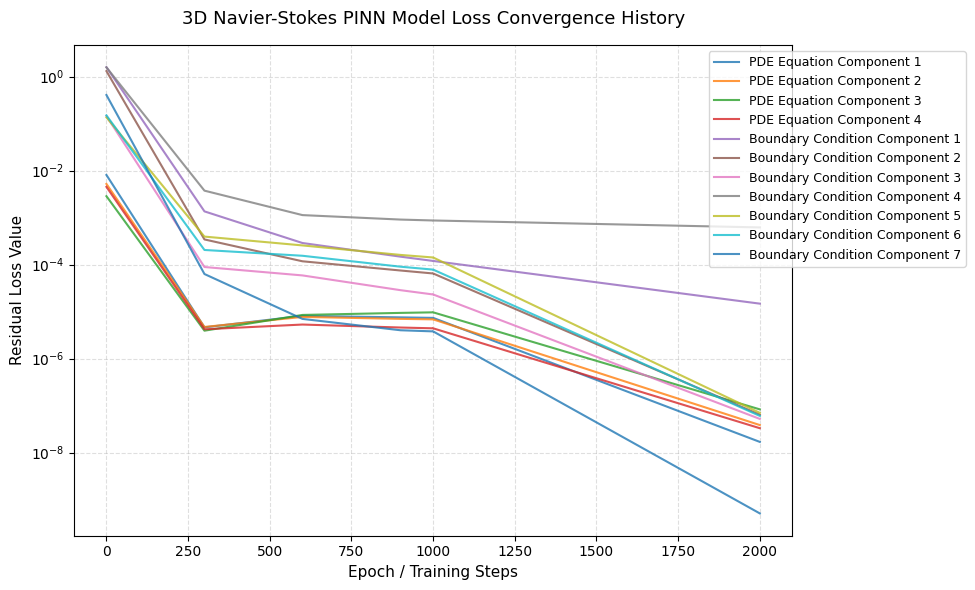

In [16]:
# 1. Access the saved loss data arrays from your DeepXDE training history
# (Ensure you ran: losshistory, train_state = model.train(...) before this)
steps = np.array(losshistory.steps)
loss_train = np.array(losshistory.loss_train)  # Shape: (Num_Steps, Num_Loss_Functions)

# 2. Set up the plotting window canvas
fig, ax = plt.subplots(figsize=(10, 6))

# 3. Graph the individual loss tracks dynamically
# DeepXDE tracks PDE losses first, followed by BC losses
num_losses = loss_train.shape[1]

for i in range(num_losses):
    if i < 4:
        # The first 4 losses belong to the 3D Navier-Stokes equations
        label_name = f"PDE Equation Component {i+1}"
    else:
        # The remaining 7 losses belong to your PointSetBC constraints
        label_name = f"Boundary Condition Component {i-3}"
        
    ax.plot(steps, loss_train[:, i], label=label_name, alpha=0.8, linewidth=1.5)

# 4. Format the plot with a logarithmic scale (crucial for PINN optimization views)
ax.set_yscale("log")
ax.set_xlabel("Epoch / Training Steps", fontsize=11)
ax.set_ylabel("Residual Loss Value", fontsize=11)
ax.set_title("3D Navier-Stokes PINN Model Loss Convergence History", fontsize=13, pad=15)

# Style configuration
ax.grid(True, which="both", linestyle="--", alpha=0.4)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0), fontsize=9)

plt.tight_layout()
print("Rendering loss tracking timeline graphs...")
plt.show()


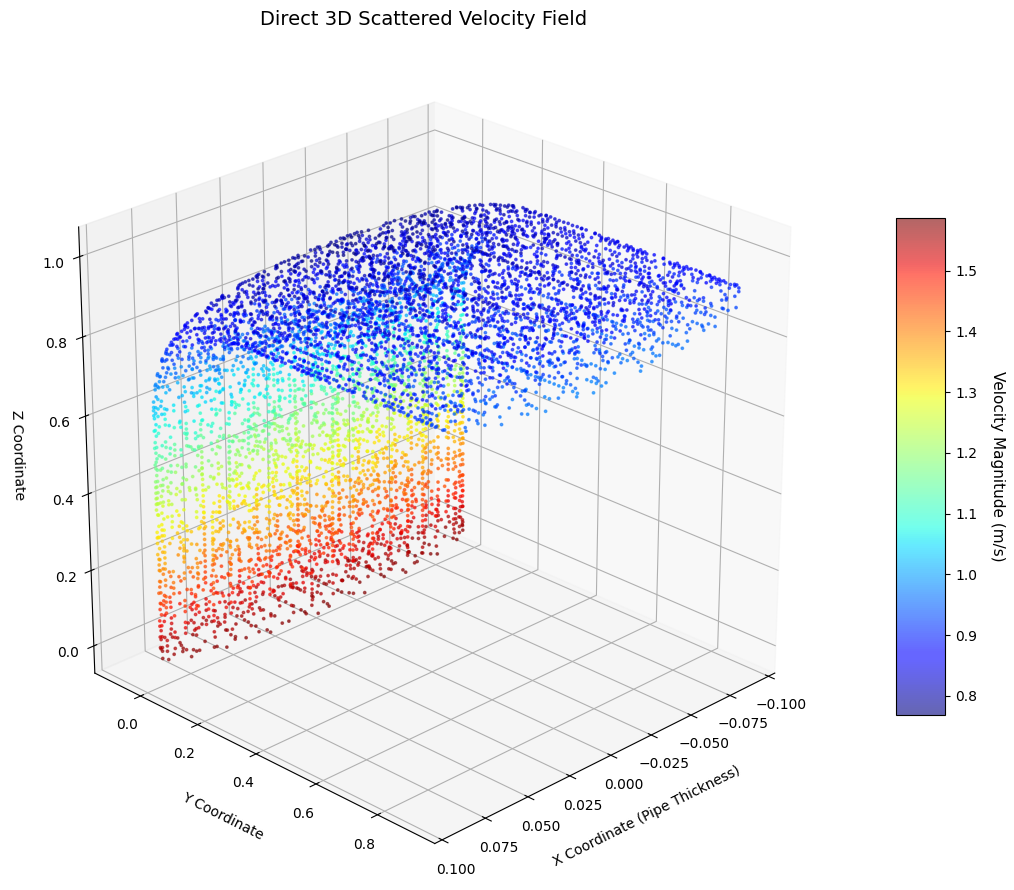

In [21]:
# 1. Generate model predictions for your true domain coordinates
predictions = model.predict(X_domain)
u_pred, v_pred, w_pred = predictions[:, 0], predictions[:, 1], predictions[:, 2]

# Calculate the True Velocity Magnitude for color mapping
vel_magnitude = np.sqrt(u_pred**2 + v_pred**2 + w_pred**2)

# 2. Initialize a 3D Canvas
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# 3. Scatter the points directly using their true X, Y, Z coordinates
# c=vel_magnitude maps the velocity array directly to the colormap colors
# [::2] downsamples the points slightly so the plot remains responsive to rotate
sc = ax.scatter(X_domain[::2, 0], X_domain[::2, 1], X_domain[::2, 2], 
                c=vel_magnitude[::2], cmap='jet', s=3, alpha=0.6)

# 4. Add a clean, descriptive Colorbar
cbar = fig.colorbar(sc, ax=ax, shrink=0.6, aspect=10)
cbar.set_label('Velocity Magnitude (m/s)', rotation=270, labelpad=20, fontsize=11)

# 5. Label your physical axes based on your Gmsh data layout
ax.set_xlabel('X Coordinate (Pipe Thickness)', fontsize=10, labelpad=10)
ax.set_ylabel('Y Coordinate', fontsize=10, labelpad=10)
ax.set_zlabel('Z Coordinate', fontsize=10, labelpad=10)
ax.set_title("Direct 3D Scattered Velocity Field", fontsize=14, pad=20)

# Adjust the viewing angle if needed (elevation, azimuth)
ax.view_init(elev=25, azim=45)

# Force equal spatial aspect ratios so the L-bend pipe does not look stretched
ax.set_box_aspect([1,1,1]) 

plt.tight_layout()
plt.show()


Rendering raw 2D node map window...


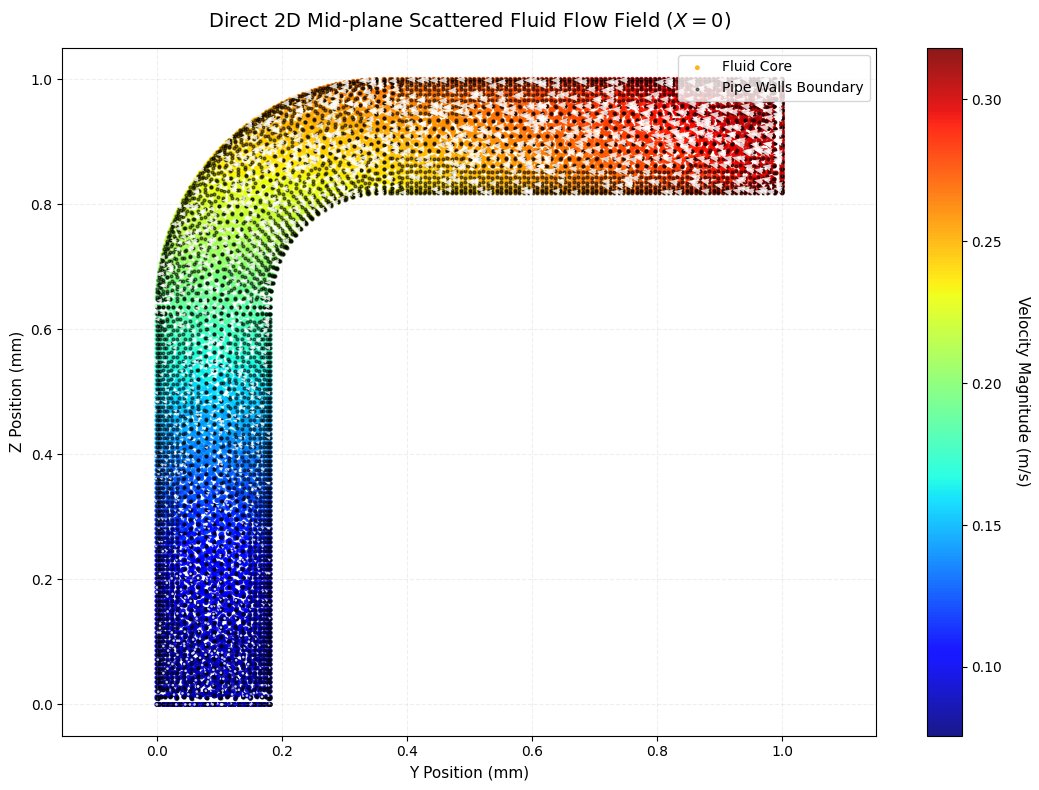

In [47]:
# 1. Predict the flow fields using your trained model
predictions = model.predict(X_domain)
u_pred, v_pred, w_pred = predictions[:, 0], predictions[:, 1], predictions[:, 2]
vel_magnitude = np.sqrt(u_pred**2 + v_pred**2 + w_pred**2)

# 2. Extract a true 2D Mid-plane Slice (Points where X is near 0)
# Adjust atol (e.g., 2.0 to 5.0) depending on how thick your mesh nodes are near the center
mid_plane_mask = np.isclose(X_domain[:, 0], 0.0, atol=4.0)

y_slice = X_domain[mid_plane_mask, 1]
z_slice = X_domain[mid_plane_mask, 2]
vel_slice = vel_magnitude[mid_plane_mask]

# Extract directional velocities for flow arrows
v_dir_slice = v_pred[mid_plane_mask]
w_dir_slice = w_pred[mid_plane_mask]

# 3. Extract wall boundary nodes to draw a crisp outer outline frame
wall_mask = np.isclose(X_walls[:, 0], 0.0, atol=4.0)
y_walls = X_walls[wall_mask, 1]
z_walls = X_walls[wall_mask, 2]

# 4. Initialize the clean 2D Canvas
fig, ax = plt.subplots(figsize=(11, 8))

# 5. Plot the fluid nodes directly using high-density scattering (Replaces contourf)
# s=12 makes the dots large enough to blend together into a solid color field
sc = ax.scatter(y_slice, z_slice, c=vel_slice, cmap='jet', s=12, alpha=0.9, edgecolors='none', label='Fluid Core')

# 6. Add a professional colorbar
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Velocity Magnitude (m/s)', rotation=270, labelpad=20, fontsize=11)

# 7. Draw the sharp black structural walls outline (Prevents bleeding visibility)
ax.scatter(y_walls, z_walls, color='black', s=4, alpha=0.5, label='Pipe Walls Boundary')

# 8. Overlay Flow Direction Arrows (Quiver Plot)
# [::10] skips points directly from your true node array to avoid clutter
skip = 10
ax.quiver(y_slice[::skip], z_slice[::skip], v_dir_slice[::skip], w_dir_slice[::skip], 
          color='white', alpha=0.8, scale=25, width=0.0035, headwidth=4)

# 9. Format labels and display
ax.set_title("Direct 2D Mid-plane Scattered Fluid Flow Field ($X=0$)", fontsize=14, pad=15)
ax.set_xlabel("Y Position (mm)", fontsize=11)
ax.set_ylabel("Z Position (mm)", fontsize=11)

ax.axis('equal')  # Strict 1:1 ratio ensures your L-bend stays a true 90-degrees
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc="upper right")

plt.tight_layout()
print("Rendering raw 2D node map window...")
plt.show()


Exporting Y-Z profile animation window timeline to 'pipe_yz_flow_simulation.gif'...
🎉 Success! Y-Z internal profile loop exported to your workspace directory.


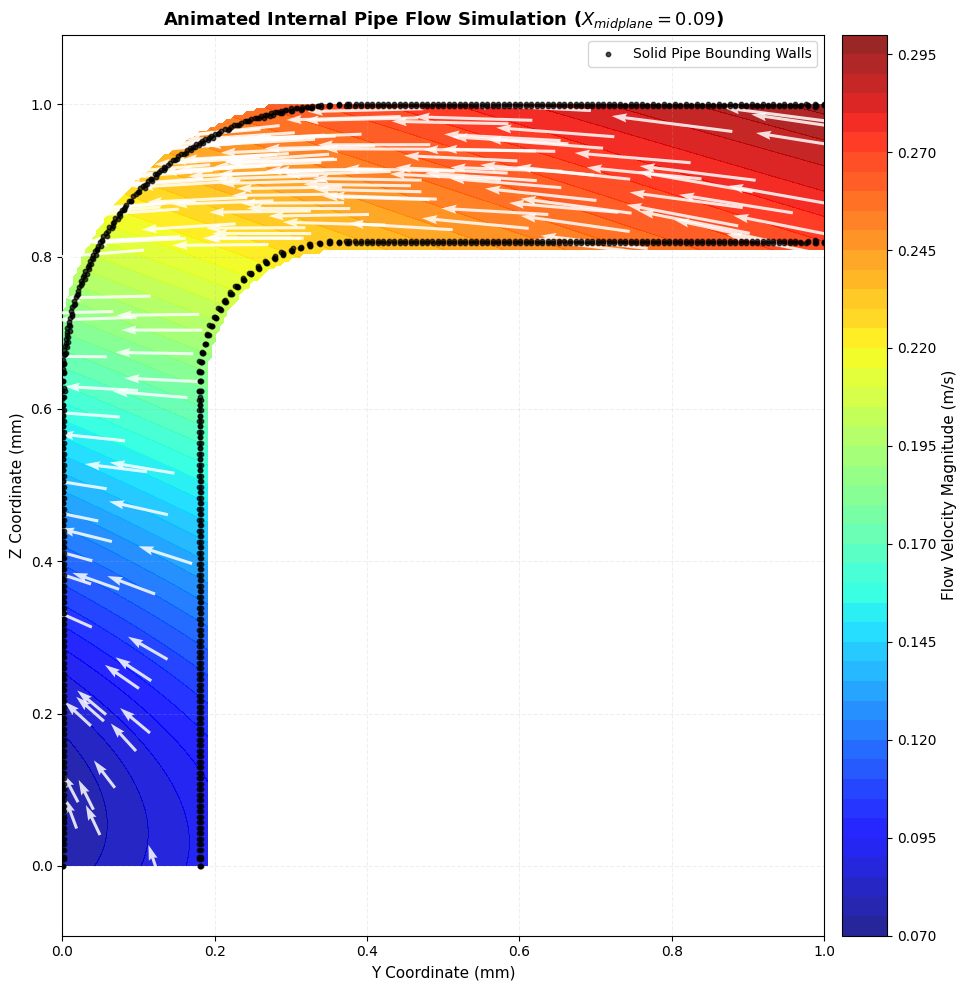

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.animation import FuncAnimation
from scipy.spatial import KDTree
from scipy.interpolate import RegularGridInterpolator

# Optimize memory ceilings for high-density rendering
mpl.rcParams['animation.embed_limit'] = 100.0  
plt.close('all')

# ==========================================
# 1. SETUP THE Y-Z PLANE GRID & PREDICT ONCE
# ==========================================
# Dynamically extract bounds from your training data coordinates
pipe_xmin, pipe_xmax = np.min(X_all_training[:, 0]), np.max(X_all_training[:, 0])
pipe_ymin, pipe_ymax = np.min(X_all_training[:, 1]), np.max(X_all_training[:, 1])
pipe_zmin, pipe_zmax = np.min(X_all_training[:, 2]), np.max(X_all_training[:, 2])

# Slice right down the middle of the X-axis (e.g. Center cross-section profile)
x_slice = (pipe_xmin + pipe_xmax) / 2.0

num_grid_points = 200
y_grid = np.linspace(pipe_ymin, pipe_ymax, num_grid_points)
z_grid = np.linspace(pipe_zmin, pipe_zmax, num_grid_points)
Y_mesh, Z_mesh = np.meshgrid(y_grid, z_grid)

Y_flat = Y_mesh.flatten()
Z_flat = Z_mesh.flatten()
X_flat = np.full_like(Y_flat, x_slice)

prediction_points = np.vstack((X_flat, Y_flat, Z_flat)).T

# Run inference ONCE via DeepXDE network model to get 3D velocity vectors
predictions = model.predict(prediction_points)
v_pred = predictions[:, 1].reshape(Y_mesh.shape)  # Y-velocity component
w_pred = predictions[:, 2].reshape(Y_mesh.shape)  # Z-velocity component

# ==========================================
# 2. APPLY Y-Z GEOMETRICAL MASKING
# ==========================================
x_tol = (pipe_xmax - pipe_xmin) * 0.15
fluid_slice_nodes = X_domain[np.abs(X_domain[:, 0] - x_slice) < x_tol]
wall_slice_nodes = X_walls[np.abs(X_walls[:, 0] - x_slice) < x_tol]

# Check layout bounds on the Y-Z grid coordinates
grid_coords_2d = np.vstack((Y_flat, Z_flat)).T
fluid_tree_2d = KDTree(fluid_slice_nodes[:, 1:3]) # Look specifically at index 1 (Y) and 2 (Z)

distances, _ = fluid_tree_2d.query(grid_coords_2d)
max_mesh_gap = (pipe_ymax - pipe_ymin) / (num_grid_points * 0.4) 
is_outside_pipe = (distances > max_mesh_gap).reshape(Y_mesh.shape)

# Preserve structural arrays for particle engines
v_fluid = np.copy(v_pred)
w_fluid = np.copy(w_pred)

# Cleanly mask regions outside the physical tube walls
v_pred[is_outside_pipe] = np.nan
w_pred[is_outside_pipe] = np.nan
velocity_magnitude = np.sqrt(v_pred**2 + w_pred**2)

# ==========================================
# 3. HIGH-SPEED Y-Z VECTOR INTERPOLATORS
# ==========================================
interp_v = RegularGridInterpolator((y_grid, z_grid), v_fluid.T, bounds_error=False, fill_value=0.0)
interp_w = RegularGridInterpolator((y_grid, z_grid), w_fluid.T, bounds_error=False, fill_value=0.0)


# ==========================================
# 3. HIGH-SPEED Y-Z VECTOR INTERPOLATORS (CORRECTED)
# ==========================================
# We append .T because v_fluid is shaped (Nz, Ny), but the grid sequence is (y_grid, z_grid)
interp_v = RegularGridInterpolator((y_grid, z_grid), v_fluid.T, bounds_error=False, fill_value=0.0)
interp_w = RegularGridInterpolator((y_grid, z_grid), w_fluid.T, bounds_error=False, fill_value=0.0)

# ==========================================
# 4. INITIALIZE DISPLAY CANVAS AESTHETICS
# ==========================================
fig, ax = plt.subplots(figsize=(10, 10)) # Square layout balances the bend structure
contour = ax.contourf(Y_mesh, Z_mesh, velocity_magnitude, levels=50, cmap='jet', alpha=0.85)
cbar = fig.colorbar(contour, ax=ax, pad=0.02)
cbar.set_label('Flow Velocity Magnitude (m/s)', fontsize=11)

# Overlay structural pipe boundary wall footprints on the Y-Z plane
ax.scatter(
    wall_slice_nodes[:, 1], 
    wall_slice_nodes[:, 2], 
    color='black', 
    s=10, 
    alpha=0.7,
    label='Solid Pipe Bounding Walls', 
    zorder=25
)

# ==========================================
# 5. Y-Z FLOW-ALIGNED PARTICLE INITIALIZATION
# ==========================================
num_particles = 150  
flat_velocities = np.sqrt(v_fluid**2 + w_fluid**2).ravel()
flat_velocities[is_outside_pipe.ravel()] = 0.0  

probabilities = flat_velocities / np.sum(flat_velocities)
chosen_indices = np.random.choice(len(Y_flat), size=num_particles, p=probabilities)

particles_y = Y_flat[chosen_indices]
particles_z = Z_flat[chosen_indices]

quiver_container = [None]

# Structural labelling properties
ax.set_xlabel('Y Coordinate (mm)', fontsize=11)
ax.set_ylabel('Z Coordinate (mm)', fontsize=11)
ax.set_title(f'Animated Internal Pipe Flow Simulation ($X_{{midplane}} = {x_slice:.2f}$)', fontsize=13, fontweight='bold')
ax.set_xlim(pipe_ymin, pipe_ymax)
ax.set_ylim(pipe_zmin, pipe_zmax)
ax.axis('equal') 
ax.grid(True, linestyle='--', alpha=0.2)
ax.legend(loc='upper right')

# ==========================================
# 6. DYNAMIC STREAM GENERATOR ENGINE
# ==========================================
num_frames = 200  
dt = 0.40         

def update_flow_animation(frame):
    global particles_y, particles_z, quiver_container
    
    if quiver_container[0] is not None:
        quiver_container[0].remove()
        
    particle_coords = np.vstack((particles_y, particles_z)).T
    
    v_p = interp_v(particle_coords)
    w_p = interp_w(particle_coords)
    
    # Progress tracers forward down the Y and Z tracking tracks
    particles_y += v_p * dt
    particles_z += w_p * dt
    
    # Evaluate tracking boundaries along the geometric arcs
    p_distances, _ = fluid_tree_2d.query(np.vstack((particles_y, particles_z)).T)
    out_of_bounds = (p_distances > max_mesh_gap) | \
                    (particles_y > pipe_ymax) | (particles_y < pipe_ymin) | \
                    (particles_z > pipe_zmax) | (particles_z < pipe_zmin)
                    
    n_respawn = np.sum(out_of_bounds)
    if n_respawn > 0:
        respawn_indices = np.random.choice(len(Y_flat), size=n_respawn, p=probabilities)
        particles_y[out_of_bounds] = Y_flat[respawn_indices]
        particles_z[out_of_bounds] = Z_flat[respawn_indices]
        
        new_coords = np.vstack((particles_y[out_of_bounds], particles_z[out_of_bounds])).T
        v_p[out_of_bounds] = interp_v(new_coords)
        w_p[out_of_bounds] = interp_w(new_coords)
        
    # Render directional indicators explicitly tracking V and W velocities
    quiver_arrows = ax.quiver(
        particles_y, particles_z, v_p, w_p,
        color='white', alpha=0.85,
        angles='xy', scale_units='xy', scale=1.8,
        pivot='mid', width=0.004, zorder=20
    )
    
    quiver_container[0] = quiver_arrows
    return quiver_arrows,

anim = FuncAnimation(fig, update_flow_animation, frames=num_frames, interval=30, blit=False)
plt.tight_layout()

# ==========================================
# 7. AUTOMATED CONVERSION FILE SAVER
# ==========================================
gif_filename = 'pipe_yz_flow_simulation.gif'
print(f"Exporting Y-Z profile animation window timeline to '{gif_filename}'...")

anim.save(gif_filename, writer='pillow', fps=30)
print(f"🎉 Success! Y-Z internal profile loop exported to your workspace directory.")
